In [1]:
# ===== CELL 1: Paths =====
# Purpose: choose where the result files are read from and where the tables and figures are written.

# SOURCE selects the data location:
#   "drive" -> the team's shared Google Drive folder that was used while the experiments were running
#   "repo"  -> the GitHub repository (use this when the notebook is submitted or re-run by a reviewer)
SOURCE      = "drive"
REPO_URL    = "https://github.com/Priyasaini7604/cot-small-llms-hindi.git"   # <- put the real repository link here (only used when SOURCE = "repo")
RESULTS_DIR = "results"    # folder with the official results; use "results_rerun" to look at a reviewer's re-run

import os, re, json, glob, subprocess   # file handling, regular expressions, JSON, file search, running git
import pandas as pd                     # tables
import matplotlib.pyplot as plt         # figures

if SOURCE == "drive":
    # Mount Google Drive in Colab and use the shared project folder
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = "/content/drive/MyDrive/DL_CoT_Project/"
else:
    ROOT = None
    # Case 1: the notebook runs inside a clone of the repository
    # (the current folder or its parent contains both results/ and data/)
    for cand in ["./", "../"]:
        if os.path.isdir(cand + RESULTS_DIR) and os.path.isdir(cand + "data"):
            ROOT = os.path.abspath(cand) + "/"
            break
    # Case 2: the notebook was opened on its own (e.g. directly from GitHub in Colab): clone the repository
    if ROOT is None:
        assert "YOUR-USERNAME" not in REPO_URL, "Set REPO_URL in Cell 1 to the real GitHub repository link (replace YOUR-USERNAME)."
        REPO_DIR = "/content/" + REPO_URL.rstrip("/").split("/")[-1].replace(".git", "") + "/"
        if not os.path.isdir(REPO_DIR):
            subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
        ROOT = REPO_DIR

RES = ROOT + RESULTS_DIR + "/"   # input folder: one JSON file per model / strategy / language run
OUT = ROOT + "analysis/"         # output folder: tables and figures
os.makedirs(OUT, exist_ok=True)  # create the output folder if it does not exist yet
print("results:", RES, "| output:", OUT)
print(len(glob.glob(RES + "*.json")), "result files found")   # should be 32 (4 models x 4 strategies x 2 languages)

Mounted at /content/drive
results: /content/drive/MyDrive/DL_CoT_Project/results/ | output: /content/drive/MyDrive/DL_CoT_Project/analysis/
32 result files found


In [2]:
# ===== CELL 2: Results table =====
# Purpose: read every result file, collect the accuracies in one table, and save it as a CSV file.

# Names of the models, strategies and languages used in the experiment grid
MODELS  = ["qwen0.5b", "qwen1.5b", "qwen3b", "qwen7b"]                       # model tags used in the result file names
SIZES   = {"qwen0.5b": "0.5B", "qwen1.5b": "1.5B", "qwen3b": "3B", "qwen7b": "7B"}   # labels for the figures
STRATS  = ["zeroshot", "fewshot", "cot", "selfcons"]                          # prompting strategies
LANGS   = ["en", "hi"]                                                        # English, Hindi

# One row per result file (= one model / strategy / language run)
rows = []
for f in sorted(glob.glob(RES + "*.json")):
    r = json.load(open(f, encoding="utf-8"))
    # "format_ok" tells whether the model output contained the requested phrase "The answer is".
    # It is only stored for single-pass strategies, so self-consistency runs have an empty list here.
    fmt = [it["format_ok"] for it in r["items"] if "format_ok" in it]
    rows.append({"model": r["model_tag"], "strategy": r["strategy"], "lang": r["lang"],
                 "acc": 100 * r["accuracy"], "n": r["n"],                    # accuracy in percent, number of questions
                 "format_ok": 100 * sum(fmt) / len(fmt) if fmt else None})   # share of outputs with the answer phrase (%)
df = pd.DataFrame(rows)
print(len(df), "/ 32 runs found")   # all 32 runs should be present

# Pivot: one row per (model, strategy), one column per language
acc = df.pivot_table(index=["model", "strategy"], columns="lang", values="acc")
for l in LANGS:
    if l not in acc.columns:        # keep both language columns even if one language has no results yet
        acc[l] = float("nan")
acc["gap_en_minus_hi"] = acc["en"] - acc["hi"]   # English-Hindi gap in accuracy points
order = [(m, s) for m in MODELS for s in STRATS if (m, s) in acc.index]   # fixed, readable row order
table = acc.loc[order].round(1)
print(table)
table.to_csv(OUT + "results_table.csv")          # save the table for the report
print("saved:", OUT + "results_table.csv")

32 / 32 runs found
lang                 en    hi  gap_en_minus_hi
model    strategy                             
qwen0.5b zeroshot   7.5   2.5              5.0
         fewshot   32.0   3.0             29.0
         cot       45.0   7.5             37.5
         selfcons  51.0   7.0             44.0
qwen1.5b zeroshot   9.5   4.5              5.0
         fewshot    8.0   6.5              1.5
         cot       72.0  31.0             41.0
         selfcons  81.0  34.5             46.5
qwen3b   zeroshot  19.0  10.5              8.5
         fewshot   17.5   9.0              8.5
         cot       81.0  59.5             21.5
         selfcons  85.5  62.5             23.0
qwen7b   zeroshot  29.5  19.0             10.5
         fewshot   29.5  21.0              8.5
         cot       90.5  67.5             23.0
         selfcons  92.5  76.0             16.5
saved: /content/drive/MyDrive/DL_CoT_Project/analysis/results_table.csv


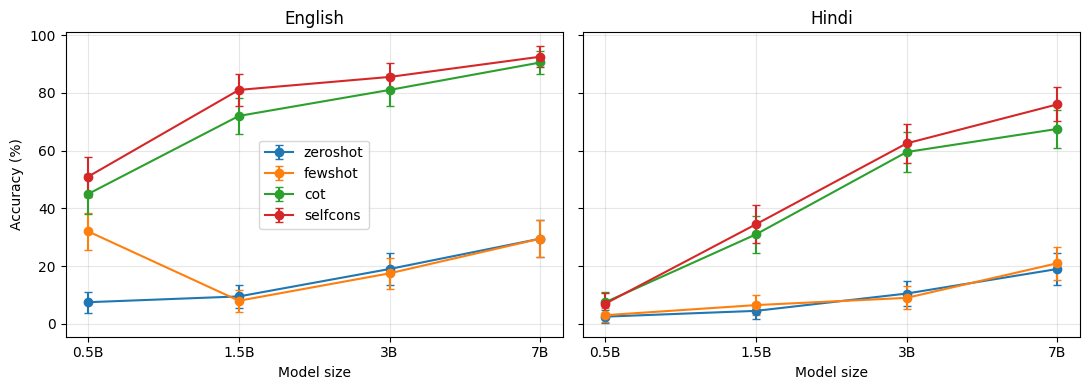

In [9]:
# ===== CELL 3: Graph 1 - model size vs accuracy (95% error bars) =====
# Purpose: plot accuracy against model size for each strategy, one panel per language.
import numpy as np

def err(p, n):          # 95% error bar in percentage points
    # normal approximation to the binomial: 1.96 * sqrt(p * (1 - p) / n), expressed in points (x100)
    p = p / 100
    return 196 * np.sqrt(p * (1 - p) / n)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)   # left panel: English, right panel: Hindi
for ax, lang in zip(axes, LANGS):
    for s in STRATS:
        xs, ys, es = [], [], []                                # x positions, accuracies, error bars
        for i, m in enumerate(MODELS):
            d = df[(df.model == m) & (df.strategy == s) & (df.lang == lang)]
            if len(d):                                         # skip runs that do not exist
                xs.append(i); ys.append(d.acc.iloc[0]); es.append(err(d.acc.iloc[0], d.n.iloc[0]))
        if xs:
            ax.errorbar(xs, ys, yerr=es, marker="o", capsize=3, label=s)   # one line per strategy
    ax.set_xticks(range(len(MODELS))); ax.set_xticklabels([SIZES[m] for m in MODELS])   # model size labels
    ax.set_title({"en": "English", "hi": "Hindi"}[lang]); ax.set_xlabel("Model size"); ax.grid(alpha=0.3)
axes[0].set_ylabel("Accuracy (%)"); axes[0].legend()           # y label and legend only on the left panel
plt.tight_layout(); plt.savefig(OUT + "fig1_size_vs_accuracy.png", dpi=150); plt.show()   # save the figure and display it

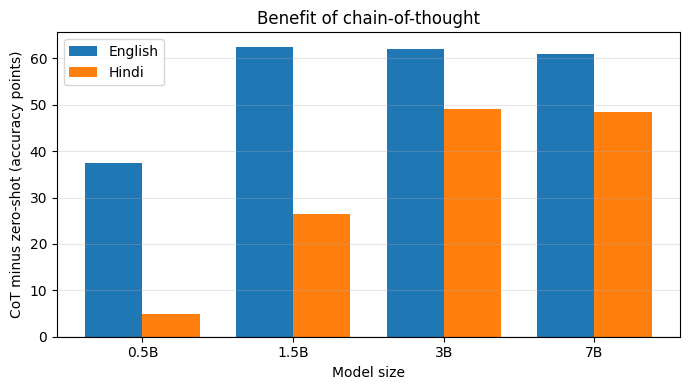

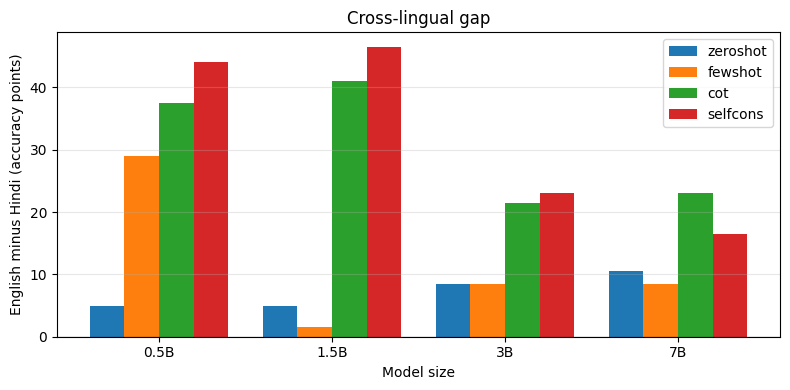

saved figures in /content/drive/MyDrive/DL_CoT_Project/analysis/


In [10]:
# ===== CELL 4: Graph 2 - benefit of CoT, Graph 3 - English vs Hindi gap =====
# Purpose: two bar charts derived from the results table.

def get(m, s, l):
    # accuracy (%) of one run (model m, strategy s, language l), or NaN if that run does not exist
    d = df[(df.model == m) & (df.strategy == s) & (df.lang == l)]
    return d.acc.iloc[0] if len(d) else np.nan

x = np.arange(len(MODELS)); w = 0.38     # one group of bars per model; w = bar width
# Graph 2: CoT minus zero-shot (how much chain-of-thought helps), English and Hindi side by side
fig, ax = plt.subplots(figsize=(7, 4))
for k, lang in enumerate(LANGS):
    vals = [get(m, "cot", lang) - get(m, "zeroshot", lang) for m in MODELS]   # gain in accuracy points per model
    ax.bar(x + (k - 0.5) * w, vals, w, label={"en": "English", "hi": "Hindi"}[lang])
ax.axhline(0, color="black", lw=0.8)     # zero line: bars above it mean CoT helped
ax.set_xticks(x); ax.set_xticklabels([SIZES[m] for m in MODELS])
ax.set_ylabel("CoT minus zero-shot (accuracy points)"); ax.set_xlabel("Model size")
ax.set_title("Benefit of chain-of-thought"); ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(OUT + "fig2_cot_benefit.png", dpi=150); plt.show()

# Graph 3: English minus Hindi (cross-lingual gap), one bar per strategy
fig, ax = plt.subplots(figsize=(8, 4))
w3 = 0.2                                 # narrower bars because there are four strategies per model
for k, s in enumerate(STRATS):
    vals = [get(m, s, "en") - get(m, s, "hi") for m in MODELS]   # gap in accuracy points per model
    ax.bar(x + (k - 1.5) * w3, vals, w3, label=s)
ax.axhline(0, color="black", lw=0.8)     # zero line: bars above it mean English is ahead of Hindi
ax.set_xticks(x); ax.set_xticklabels([SIZES[m] for m in MODELS])
ax.set_ylabel("English minus Hindi (accuracy points)"); ax.set_xlabel("Model size")
ax.set_title("Cross-lingual gap"); ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig(OUT + "fig3_language_gap.png", dpi=150); plt.show()
print("saved figures in", OUT)

In [3]:
# ===== CELL 5: Diagnostics (settings, output length, format) =====
# Purpose: accuracy alone does not show HOW the models behaved. This cell checks that all runs used the
# same settings, how long the outputs are, and how often the model followed the requested answer format.
import numpy as np
rows = []
for f in sorted(glob.glob(RES + "*.json")):                  # one result file per model / strategy / language
    r = json.load(open(f, encoding="utf-8"))
    if r["strategy"] == "selfcons":
        # self-consistency stores five outputs per question; all of them are used for the length
        lens, fmt = [len(o) for it in r["items"] for o in it["outputs"]], None   # no answer-format flag for this strategy
    else:
        lens = [len(it["output"]) for it in r["items"]]
        fmt = 100 * np.mean([it.get("format_ok", False) for it in r["items"]])   # share of outputs with "The answer is"
    s = r.get("settings", {})                                # settings that were saved together with the run
    rows.append({"model": r["model_tag"], "strategy": r["strategy"], "lang": r["lang"],
                 "avg_chars": round(np.mean(lens)), "format_ok": None if fmt is None else round(fmt),
                 "4bit": s.get("4bit"), "bs": s.get("batch_size"), "seed": s.get("seed"),
                 "max_tok": s.get("max_new_tokens"), "sc": s.get("sc_samples"), "n": r["n"]})
diag = pd.DataFrame(rows)
order = [(m, s) for m in MODELS for s in STRATS]             # fixed, readable row order

print("== Average output length (characters) ==")
print(diag.pivot_table(index=["model", "strategy"], columns="lang", values="avg_chars").reindex(order))
print("\n== Outputs that contain the requested phrase 'The answer is' (%) ==")
print(diag.pivot_table(index=["model", "strategy"], columns="lang", values="format_ok").reindex(order))
print("\n== Settings consistency ==")
print(diag.groupby(["model", "lang"])["4bit"].agg(lambda x: sorted(set(map(str, x)))).unstack())   # 4-bit used? (should be True only for 7B)
print({k: sorted(set(map(str, diag[k]))) for k in ["seed", "max_tok", "sc", "n"]})                 # each list should hold one value

== Average output length (characters) ==
lang                  en     hi
model    strategy              
qwen0.5b zeroshot  158.0   21.0
         fewshot   800.0   17.0
         cot       881.0  846.0
         selfcons  901.0  894.0
qwen1.5b zeroshot   17.0   18.0
         fewshot    73.0   19.0
         cot       801.0  832.0
         selfcons  810.0  822.0
qwen3b   zeroshot   17.0   18.0
         fewshot    78.0   17.0
         cot       824.0  743.0
         selfcons  817.0  731.0
qwen7b   zeroshot   18.0   18.0
         fewshot    17.0   18.0
         cot       835.0  511.0
         selfcons  845.0  518.0

== Outputs that contain the requested phrase 'The answer is' (%) ==
lang                  en     hi
model    strategy              
qwen0.5b zeroshot   86.0   98.0
         fewshot    33.0  100.0
         cot        82.0   94.0
         selfcons    NaN    NaN
qwen1.5b zeroshot   98.0  100.0
         fewshot    70.0   98.0
         cot        86.0   92.0
         selfcons    NaN  

In [4]:
# ===== CELL 6: Paired bootstrap (is a difference larger than noise?) =====
# Purpose: every strategy was evaluated on the same 200 questions, and every Hindi question is the
# translation of the English question with the same id, so differences can be estimated with a PAIRED
# bootstrap: resample the 200 question ids with replacement (10,000 times), recompute the accuracy
# difference on every resample, and use the 2.5th and 97.5th percentiles as a 95% interval.
# A difference is called "clear" when this interval does not contain zero.
rng = np.random.default_rng(0)       # fixed seed so that the intervals are reproducible

def load_correct(m, s, l):
    # 0/1 vector of per-question correctness for one run, ordered by question id (so that two runs are paired)
    r = json.load(open(RES + f"{m}_{s}_{l}.json", encoding="utf-8"))
    items = sorted(r["items"], key=lambda it: it["id"])
    return np.array([it["correct"] for it in items], dtype=float)

def boot(a, b, B=10000):
    # accuracy difference a - b in points, with a 95% bootstrap interval
    idx = rng.integers(0, len(a), size=(B, len(a)))               # resampled question indices
    d = 100 * (a[idx].mean(axis=1) - b[idx].mean(axis=1))         # accuracy difference on each resample
    return 100 * (a.mean() - b.mean()), np.percentile(d, 2.5), np.percentile(d, 97.5)

rows = []
for m in MODELS:
    # (a) differences between strategies within one language
    for lang in LANGS:
        for name, (s1, s2) in {"CoT - zeroshot": ("cot", "zeroshot"),
                               "selfcons - CoT": ("selfcons", "cot"),
                               "fewshot - zeroshot": ("fewshot", "zeroshot")}.items():
            d, lo, hi = boot(load_correct(m, s1, lang), load_correct(m, s2, lang))
            rows.append({"model": SIZES[m], "comparison": name, "lang": lang, "diff": d, "ci_low": lo, "ci_high": hi})
    # (b) English minus Hindi within one strategy
    for s in STRATS:      # English - Hindi, same questions (paired by id)
        d, lo, hi = boot(load_correct(m, s, "en"), load_correct(m, s, "hi"))
        rows.append({"model": SIZES[m], "comparison": f"EN - HI ({s})", "lang": "-", "diff": d, "ci_low": lo, "ci_high": hi})

sig = pd.DataFrame(rows)
sig["clear"] = ((sig.ci_low > 0) | (sig.ci_high < 0)).map({True: "yes", False: "no"})   # does the interval exclude zero?
print(sig.round(1).to_string(index=False))
sig.round(2).to_csv(OUT + "significance.csv", index=False)       # save for the report (Table 3)
print("saved:", OUT + "significance.csv")

model         comparison lang  diff  ci_low  ci_high clear
 0.5B     CoT - zeroshot   en  37.5    30.0     45.0   yes
 0.5B     selfcons - CoT   en   6.0    -0.5     12.5    no
 0.5B fewshot - zeroshot   en  24.5    17.5     31.5   yes
 0.5B     CoT - zeroshot   hi   5.0     1.0      9.0   yes
 0.5B     selfcons - CoT   hi  -0.5    -5.0      4.5    no
 0.5B fewshot - zeroshot   hi   0.5    -2.5      4.0    no
 0.5B EN - HI (zeroshot)    -   5.0     1.0      9.5   yes
 0.5B  EN - HI (fewshot)    -  29.0    22.0     36.0   yes
 0.5B      EN - HI (cot)    -  37.5    30.5     45.0   yes
 0.5B EN - HI (selfcons)    -  44.0    37.0     51.5   yes
 1.5B     CoT - zeroshot   en  62.5    55.0     69.5   yes
 1.5B     selfcons - CoT   en   9.0     3.5     14.5   yes
 1.5B fewshot - zeroshot   en  -1.5    -6.0      3.0    no
 1.5B     CoT - zeroshot   hi  26.5    20.0     33.5   yes
 1.5B     selfcons - CoT   hi   3.5    -2.5      9.5    no
 1.5B fewshot - zeroshot   hi   2.0    -2.5      6.5    

In [5]:
# ===== CELL 7: Extraction check + language of the Hindi outputs =====
# Purpose: (1) if the phrase "The answer is" is missing, the pipeline falls back to the last number in the
# output; this part counts such CoT outputs and compares their accuracy with well-formatted outputs.
# (2) it counts how many Hindi CoT outputs are written mostly in Devanagari (Hindi script).
def acc(L):
    # accuracy in percent of a list of True/False flags (NaN for an empty list)
    return 100 * np.mean(L) if L else float("nan")

for m in MODELS:
    for lang in LANGS:
        r = json.load(open(RES + f"{m}_cot_{lang}.json", encoding="utf-8"))
        ok  = [it["correct"] for it in r["items"] if it["format_ok"]]        # outputs with "The answer is"
        bad = [it["correct"] for it in r["items"] if not it["format_ok"]]    # outputs without it
        print(f"{SIZES[m]:5s} {lang} CoT | with phrase: {len(ok):3d} (acc {acc(ok):5.1f}%) | without phrase: {len(bad):3d} (acc {acc(bad):5.1f}%)")

print()
for m in MODELS:
    r = json.load(open(RES + f"{m}_cot_hi.json", encoding="utf-8"))
    # share of Devanagari characters (Unicode block U+0900-U+097F) in each output
    dev = [sum("\u0900" <= ch <= "\u097F" for ch in it["output"]) / max(len(it["output"]), 1) for it in r["items"]]
    print(SIZES[m], "Hindi CoT: outputs with more than 20% Devanagari characters:", sum(d > 0.2 for d in dev), "/ 200")

0.5B  en CoT | with phrase: 165 (acc  48.5%) | without phrase:  35 (acc  28.6%)
0.5B  hi CoT | with phrase: 189 (acc   7.4%) | without phrase:  11 (acc   9.1%)
1.5B  en CoT | with phrase: 172 (acc  75.6%) | without phrase:  28 (acc  50.0%)
1.5B  hi CoT | with phrase: 185 (acc  31.9%) | without phrase:  15 (acc  20.0%)
3B    en CoT | with phrase: 193 (acc  83.9%) | without phrase:   7 (acc   0.0%)
3B    hi CoT | with phrase: 192 (acc  62.0%) | without phrase:   8 (acc   0.0%)
7B    en CoT | with phrase: 196 (acc  92.3%) | without phrase:   4 (acc   0.0%)
7B    hi CoT | with phrase: 185 (acc  70.3%) | without phrase:  15 (acc  33.3%)

0.5B Hindi CoT: outputs with more than 20% Devanagari characters: 0 / 200
1.5B Hindi CoT: outputs with more than 20% Devanagari characters: 0 / 200
3B Hindi CoT: outputs with more than 20% Devanagari characters: 9 / 200
7B Hindi CoT: outputs with more than 20% Devanagari characters: 0 / 200


In [6]:
# ===== CELL 8: Example outputs without the answer phrase (truncation examples) =====
# Purpose: show the END of outputs that do not contain "The answer is". Outputs that stop in the middle of
# an equation or number were cut off by the 512-token limit; the Chinese outputs of the 7B model are visible too.
for m, lang in [("qwen3b", "en"), ("qwen7b", "en"), ("qwen7b", "hi")]:
    r = json.load(open(RES + f"{m}_cot_{lang}.json", encoding="utf-8"))
    bad = [it for it in r["items"] if not it["format_ok"]][:2]       # the first two outputs without the phrase
    for it in bad:
        print(m, lang, "id", it["id"], "| pred:", it["pred"], "| gt:", it["gt"], "| correct:", it["correct"])
        print("...", it["output"][-250:].replace("\n", " "))          # last 250 characters of the output
        print("-" * 60)

qwen3b en id 13 | pred: 1 | gt: 18 | correct: False
... rac{2x}{3} - 2 - \left( \frac{x}{3} - 1 \right) = 5 \]  Simplify inside the parentheses:  \[ \frac{2x}{3} - 2 - \frac{x}{3} + 1 = 5 \]  Combine like terms:  \[ \frac{2x - x}{3} - 1 = 5 \]  \[ \frac{x}{3} - 1 = 5 \]  Add 1 to both sides:  \[ \frac{x}{
------------------------------------------------------------
qwen3b en id 20 | pred: 36 | gt: 15 | correct: False
... nal mixture:  - Percentage of water in the final mixture: \( \frac{\frac{46}{3}}{24} = \frac{46}{72} = \frac{23}{36} \).  To find the exact amount of water in the 24 liters:  - Amount of water in 24 liters: \( 24 \times \frac{23}{36} = \frac{552}{36}
------------------------------------------------------------
qwen7b en id 62 | pred: 5 | gt: 25000 | correct: False
... tional annual payment} = 5\% \times V \]  Since the exact calculation involves complex financial mathematics, we can approximate the additional annual payment as: \[ \text{Additional annual payment} \appr

In [7]:
# ===== CELL 9: Language of the CoT outputs (Chinese / Hindi / English) and its accuracy =====
# Purpose: the prompt does not say which language to reason in. Each output is assigned to a language
# group using the share of its characters that belong to the Chinese and Devanagari Unicode blocks.
def bucket(t):
    n = max(len(t), 1)                                              # avoid division by zero for empty outputs
    cjk = sum("\u4e00" <= ch <= "\u9fff" for ch in t) / n           # share of Chinese (CJK) characters
    dev = sum("\u0900" <= ch <= "\u097f" for ch in t) / n           # share of Devanagari (Hindi) characters
    return "chinese" if cjk > 0.1 else ("hindi" if dev > 0.2 else "english/other")   # everything else: mostly English

for lang in LANGS:
    print(f"== CoT, {lang.upper()} questions ==")
    for m in MODELS:
        r = json.load(open(RES + f"{m}_cot_{lang}.json", encoding="utf-8"))
        groups = {}                                                 # language group -> correctness flags
        for it in r["items"]:
            groups.setdefault(bucket(it["output"]), []).append(it["correct"])
        parts = [f"{b}: {len(v)} (acc {100 * np.mean(v):.1f}%)" for b, v in sorted(groups.items())]
        print(f"{SIZES[m]:5s} | " + " | ".join(parts))

== CoT, EN questions ==
0.5B  | english/other: 200 (acc 45.0%)
1.5B  | english/other: 200 (acc 72.0%)
3B    | english/other: 200 (acc 81.0%)
7B    | english/other: 200 (acc 90.5%)
== CoT, HI questions ==
0.5B  | english/other: 200 (acc 7.5%)
1.5B  | english/other: 200 (acc 31.0%)
3B    | english/other: 191 (acc 59.7%) | hindi: 9 (acc 55.6%)
7B    | chinese: 135 (acc 65.9%) | english/other: 65 (acc 70.8%)


In [11]:
# ===== CELL 10: Hindi accuracy as a percentage of English accuracy =====
# Purpose: the report quotes Hindi accuracy relative to English (Section 4.3: 17%, 43%, 73%, 75% under CoT).
# The values are computed from the accuracies in df with get() from Cell 4.
relative = pd.DataFrame({s: [100 * get(m, s, "hi") / get(m, s, "en") for m in MODELS] for s in STRATS},
                        index=[SIZES[m] for m in MODELS]).round(0)   # rows: model size, columns: strategy
print("Hindi accuracy as % of English accuracy:")
print(relative)
relative.to_csv(OUT + "hindi_relative_to_english.csv")                # save for the report
print("saved:", OUT + "hindi_relative_to_english.csv")

Hindi accuracy as % of English accuracy:
      zeroshot  fewshot   cot  selfcons
0.5B      33.0      9.0  17.0      14.0
1.5B      47.0     81.0  43.0      43.0
3B        55.0     51.0  73.0      73.0
7B        64.0     71.0  75.0      82.0
saved: /content/drive/MyDrive/DL_CoT_Project/analysis/hindi_relative_to_english.csv
